In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Chua co GPU. Hay kiem tra Runtime type.")


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
from pathlib import Path
import zipfile
import os

zip_path = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/"
    "segmentation_preprocessed_256.zip"
)

assert zip_path.exists(), (
    f"Khong tim thay file ZIP: {zip_path}. "
    "Hay kiem tra ten file va thu muc tren Google Drive."
)

with zipfile.ZipFile(zip_path, "r") as z:
    for member in z.infolist():
        # Thay the \ bang / de tao dung thu muc tren Linux
        normalized_path = member.filename.replace("\\", "/")
        target_path = os.path.join("/content", normalized_path)

        # Neu duong dan ket thuc bang '/' hoac la directory thi tao thu muc
        if member.is_dir() or normalized_path.endswith("/"):
            os.makedirs(target_path, exist_ok=True)
        else:
            # Tao thu muc cha neu chua co
            os.makedirs(os.path.dirname(target_path), exist_ok=True)
            with z.open(member) as source, open(target_path, "wb") as target:
                target.write(source.read())

DATA_DIR = Path("/content/preprocessed_256")

for split in ["train", "validation", "test"]:
    image_dir = DATA_DIR / split / "images"
    mask_dir = DATA_DIR / split / "masks"

    assert image_dir.exists(), f"Thieu: {image_dir}"
    assert mask_dir.exists(), f"Thieu: {mask_dir}"

    print(
        split,
        "| images:", len(list(image_dir.glob("*.png"))),
        "| masks:", len(list(mask_dir.glob("*.png")))
    )

train | images: 271 | masks: 271
validation | images: 68 | masks: 68
test | images: 146 | masks: 146


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Đang chạy CPU")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
from pathlib import Path
import torch

DATA_DIR = Path("/content/preprocessed_256")

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREP_DIR = DATA_DIR

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", DEVICE)

Training device: cuda


In [ ]:

from pathlib import Path
import torch

# 1. Kiểm tra dữ liệu
DATA_DIR = Path("/content/preprocessed_256")

for split in ["train", "validation", "test"]:
    image_dir = DATA_DIR / split / "images"
    mask_dir = DATA_DIR / split / "masks"

    print(
        f"{split}: "
        f"images={len(list(image_dir.glob('*.png'))) if image_dir.exists() else 'MISSING'}, "
        f"masks={len(list(mask_dir.glob('*.png'))) if mask_dir.exists() else 'MISSING'}"
    )

# 2. Kiểm tra Google Drive
drive_dir = Path("/content/drive/MyDrive")
print("\nGoogle Drive connected:", drive_dir.exists())

# 3. Kiểm tra thiết bị
print("Training device:", "cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


train: images=271, masks=271
validation: images=68, masks=68
test: images=146, masks=146

Google Drive connected: True
Training device: cuda
GPU: Tesla T4


In [ ]:
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)
print("Ready:", OUTPUT_DIR.exists())

Output directory: /content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results
Ready: True


In [ ]:

import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()

        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(64, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = DoubleConv(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)

        self.out_conv = nn.Conv2d(16, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out_conv(d1)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet(num_classes=3).to(DEVICE)

print("Device:", DEVICE)
print("Model:", type(model).__name__)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")


Device: cuda
Model: UNet
Parameters: 482,067


In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

DATA_DIR = Path("/content/preprocessed_256")
BATCH_SIZE = 4

class FundusDataset(Dataset):
    def __init__(self, split):
        self.image_dir = DATA_DIR / split / "images"
        self.mask_dir = DATA_DIR / split / "masks"
        self.images = sorted(self.image_dir.glob("*.png"))

        if not self.images:
            raise RuntimeError(f"Khong tim thay anh trong {split}")

        for image_path in self.images:
            if not (self.mask_dir / image_path.name).exists():
                raise FileNotFoundError(
                    f"Thieu mask: {image_path.name}"
                )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_path = self.images[idx]
        mask_path = self.mask_dir / image_path.name

        with Image.open(image_path) as im:
            image = np.array(
                im.convert("RGB"), dtype=np.float32
            ) / 255.0

        with Image.open(mask_path) as im:
            mask = np.array(im.convert("L"), dtype=np.uint8)

        if not np.isin(mask, [0, 1, 2]).all():
            raise ValueError(f"Nhãn không hợp lệ: {mask_path}")

        image = torch.from_numpy(
            image.transpose(2, 0, 1).copy()
        )
        mask = torch.from_numpy(mask.astype(np.int64))

        return image, mask


train_ds = FundusDataset("train")
val_ds = FundusDataset("validation")
test_ds = FundusDataset("test")

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

images, masks = next(iter(train_loader))

print("Train samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Test samples:", len(test_ds))
print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Mask labels:", torch.unique(masks).tolist())


Train samples: 271
Validation samples: 68
Test samples: 146
Image batch shape: torch.Size([4, 3, 256, 256])
Mask batch shape: torch.Size([4, 256, 256])
Mask labels: [0, 1, 2]


In [ ]:

import torch
import torch.nn as nn

# Loss cho bài toán phân đoạn 3 lớp
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate:", 1e-3)
print("Device:", next(model.parameters()).device)


Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001
Device: cuda:0


Epoch 01/30 | Train loss=0.9251 | Val loss=0.8038 | Val Disc Dice=0.0000 | Val Cup Dice=0.0000
  -> Saved best checkpoint to Google Drive
Epoch 02/30 | Train loss=0.8155 | Val loss=0.8080 | Val Disc Dice=0.2183 | Val Cup Dice=0.0000
Epoch 03/30 | Train loss=0.7727 | Val loss=0.7898 | Val Disc Dice=0.5193 | Val Cup Dice=0.0000
  -> Saved best checkpoint to Google Drive
Epoch 04/30 | Train loss=0.7491 | Val loss=0.7465 | Val Disc Dice=0.2904 | Val Cup Dice=0.0000
  -> Saved best checkpoint to Google Drive
Epoch 05/30 | Train loss=0.7193 | Val loss=0.7209 | Val Disc Dice=0.4908 | Val Cup Dice=0.0189
  -> Saved best checkpoint to Google Drive
Epoch 06/30 | Train loss=0.7072 | Val loss=0.6918 | Val Disc Dice=0.4137 | Val Cup Dice=0.3576
  -> Saved best checkpoint to Google Drive
Epoch 07/30 | Train loss=0.7069 | Val loss=0.6864 | Val Disc Dice=0.4899 | Val Cup Dice=0.0000
  -> Saved best checkpoint to Google Drive
Epoch 08/30 | Train loss=0.7047 | Val loss=0.7371 | Val Disc Dice=0.4784 | Va

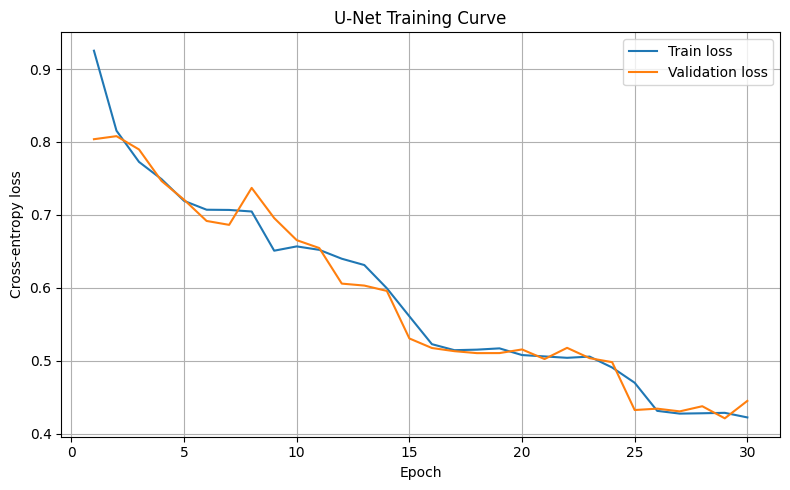


Training finished.
Best validation loss: 0.4212
Elapsed: 3.1 minutes
Results saved to: /content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results


In [ ]:

import csv
import time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import torch

# Kiểm tra các biến từ các bước trước
assert "model" in globals()
assert "train_loader" in globals()
assert "val_loader" in globals()
assert "criterion" in globals()
assert "optimizer" in globals()

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 30
best_val_loss = float("inf")
history = []

def dice_score(pred, target, class_id):
    pred_mask = pred == class_id
    target_mask = target == class_id

    intersection = (pred_mask & target_mask).sum().item()
    denominator = pred_mask.sum().item() + target_mask.sum().item()

    if denominator == 0:
        return float("nan")

    return 2.0 * intersection / denominator


def run_epoch(loader, training):
    model.train(training)

    total_loss = 0.0
    total_images = 0
    disc_scores = []
    cup_scores = []

    context = torch.enable_grad if training else torch.no_grad

    with context():
        for images, masks in loader:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            if training:
                optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, masks)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_images += batch_size

            predictions = torch.argmax(logits, dim=1)

            for i in range(batch_size):
                disc_scores.append(
                    dice_score(predictions[i], masks[i], 1)
                )
                cup_scores.append(
                    dice_score(predictions[i], masks[i], 2)
                )

    return (
        total_loss / total_images,
        float(np.nanmean(disc_scores)),
        float(np.nanmean(cup_scores)),
    )


start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_disc, train_cup = run_epoch(
        train_loader, training=True
    )

    val_loss, val_disc, val_cup = run_epoch(
        val_loader, training=False
    )

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_disc_dice": train_disc,
        "train_cup_dice": train_cup,
        "val_disc_dice": val_disc,
        "val_cup_dice": val_cup,
    }
    history.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss={train_loss:.4f} | "
        f"Val loss={val_loss:.4f} | "
        f"Val Disc Dice={val_disc:.4f} | "
        f"Val Cup Dice={val_cup:.4f}"
    )

    if np.isfinite(val_loss) and val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
            },
            OUTPUT_DIR / "best_unet.pt",
        )
        print("  -> Saved best checkpoint to Google Drive")

# Lưu lịch sử
history_path = OUTPUT_DIR / "training_history.csv"
with open(history_path, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=history[0].keys())
    writer.writeheader()
    writer.writerows(history)

# Vẽ loss curve
epochs = [r["epoch"] for r in history]

plt.figure(figsize=(8, 5))
plt.plot(epochs, [r["train_loss"] for r in history], label="Train loss")
plt.plot(epochs, [r["val_loss"] for r in history], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("U-Net Training Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=150)
plt.show()
plt.close()

print("\nTraining finished.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Elapsed: {(time.time() - start_time) / 60:.1f} minutes")
print(f"Results saved to: {OUTPUT_DIR}")


Best epoch: 29
Best validation loss: 0.4211825377800885


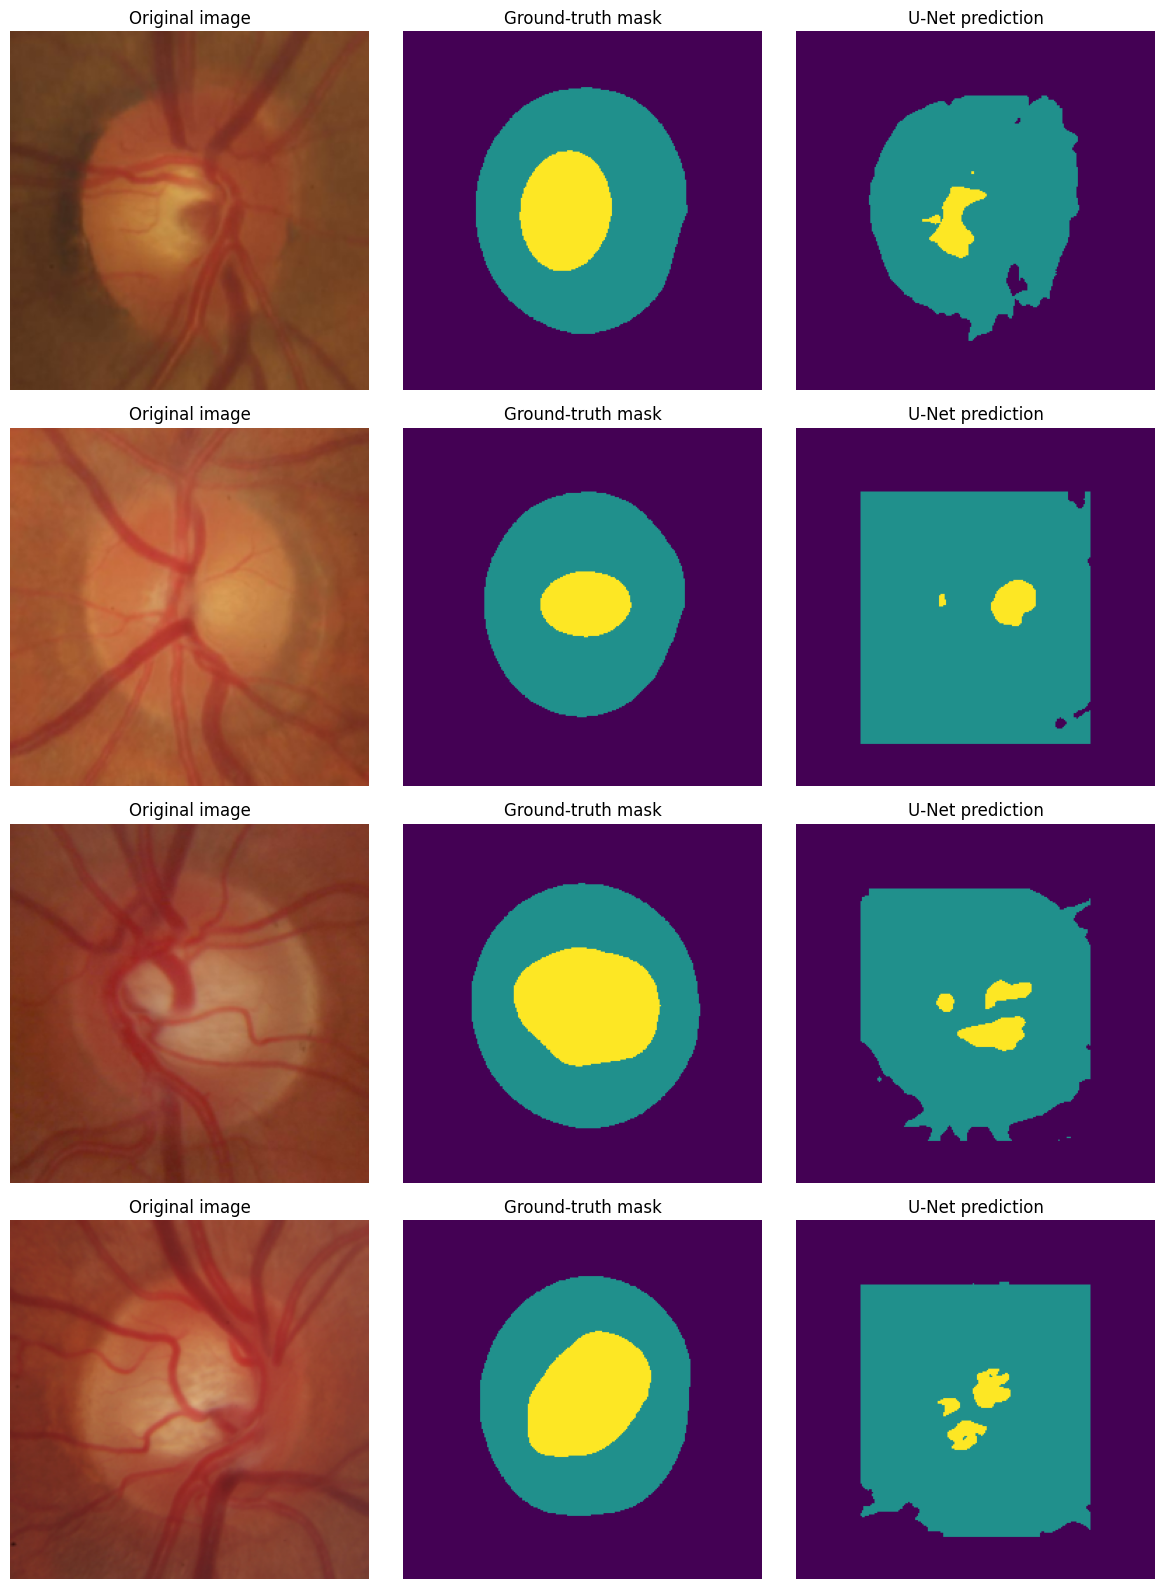

Saved visualization: /content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results/validation_predictions.png


In [ ]:

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
checkpoint_path = OUTPUT_DIR / "best_unet.pt"

# Tải checkpoint tốt nhất
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

# Lấy 4 ảnh đầu tiên từ validation set
num_show = min(4, len(val_ds))
fig, axes = plt.subplots(num_show, 3, figsize=(12, 4 * num_show))

if num_show == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for i in range(num_show):
        image_tensor, true_mask = val_ds[i]
        logits = model(image_tensor.unsqueeze(0).to(DEVICE))
        pred_mask = torch.argmax(logits, dim=1)[0].cpu().numpy()

        image = image_tensor.permute(1, 2, 0).numpy()
        true_mask = true_mask.numpy()

        axes[i, 0].imshow(image)
        axes[i, 0].set_title("Original image")

        axes[i, 1].imshow(true_mask, vmin=0, vmax=2, cmap="viridis")
        axes[i, 1].set_title("Ground-truth mask")

        axes[i, 2].imshow(pred_mask, vmin=0, vmax=2, cmap="viridis")
        axes[i, 2].set_title("U-Net prediction")

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_predictions.png", dpi=150)
plt.show()

print("Saved visualization:", OUTPUT_DIR / "validation_predictions.png")


Sample 0: image=(256, 256, 3), mask=(256, 256), labels=[0, 1, 2], background=0.627, disc_only=0.266, cup=0.107
Sample 1: image=(256, 256, 3), mask=(256, 256), labels=[0, 1, 2], background=0.554, disc_only=0.287, cup=0.159
Sample 2: image=(256, 256, 3), mask=(256, 256), labels=[0, 1, 2], background=0.625, disc_only=0.319, cup=0.056
Sample 3: image=(256, 256, 3), mask=(256, 256), labels=[0, 1, 2], background=0.621, disc_only=0.303, cup=0.076


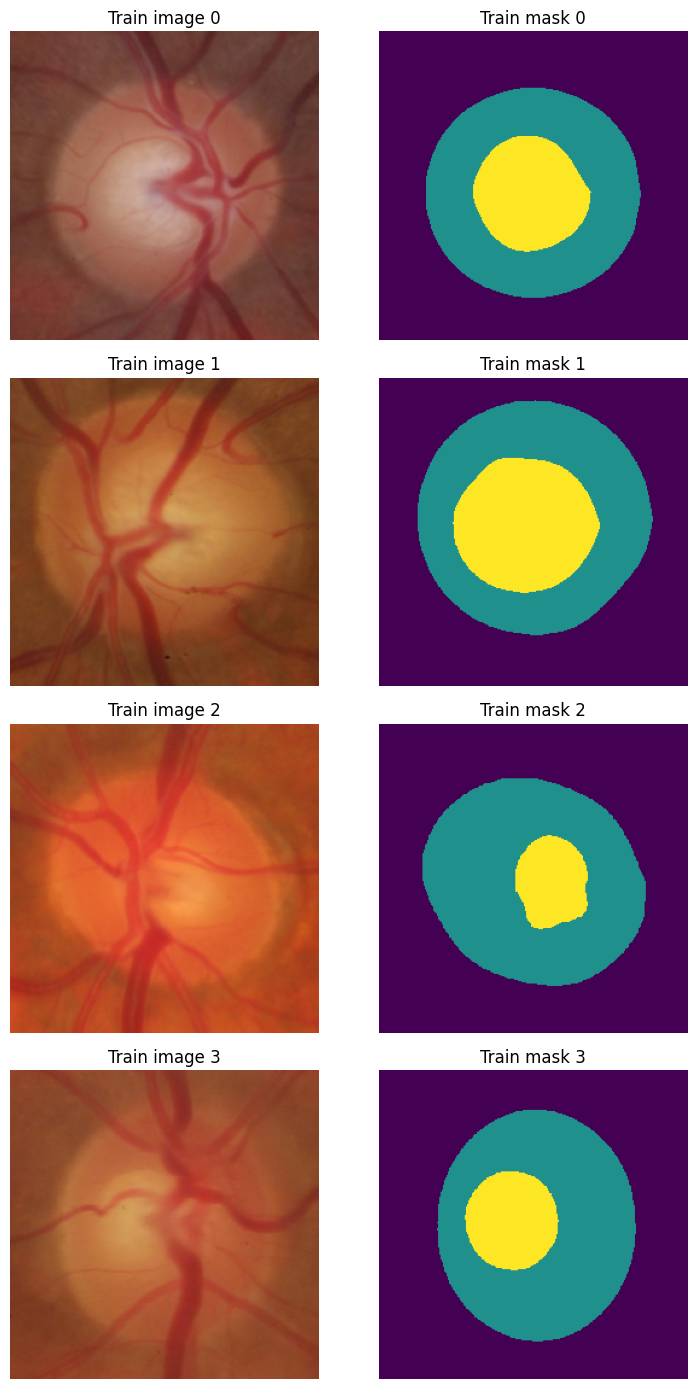

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Kiểm tra 4 mẫu đầu tiên của tập train
fig, axes = plt.subplots(4, 2, figsize=(8, 14))

for i in range(4):
    image, mask = train_ds[i]
    image_np = image.permute(1, 2, 0).numpy()
    mask_np = mask.numpy()

    print(
        f"Sample {i}: image={image_np.shape}, "
        f"mask={mask_np.shape}, "
        f"labels={np.unique(mask_np).tolist()}, "
        f"background={(mask_np == 0).mean():.3f}, "
        f"disc_only={(mask_np == 1).mean():.3f}, "
        f"cup={(mask_np == 2).mean():.3f}"
    )

    axes[i, 0].imshow(image_np)
    axes[i, 0].set_title(f"Train image {i}")
    axes[i, 1].imshow(mask_np, vmin=0, vmax=2, cmap="viridis")
    axes[i, 1].set_title(f"Train mask {i}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


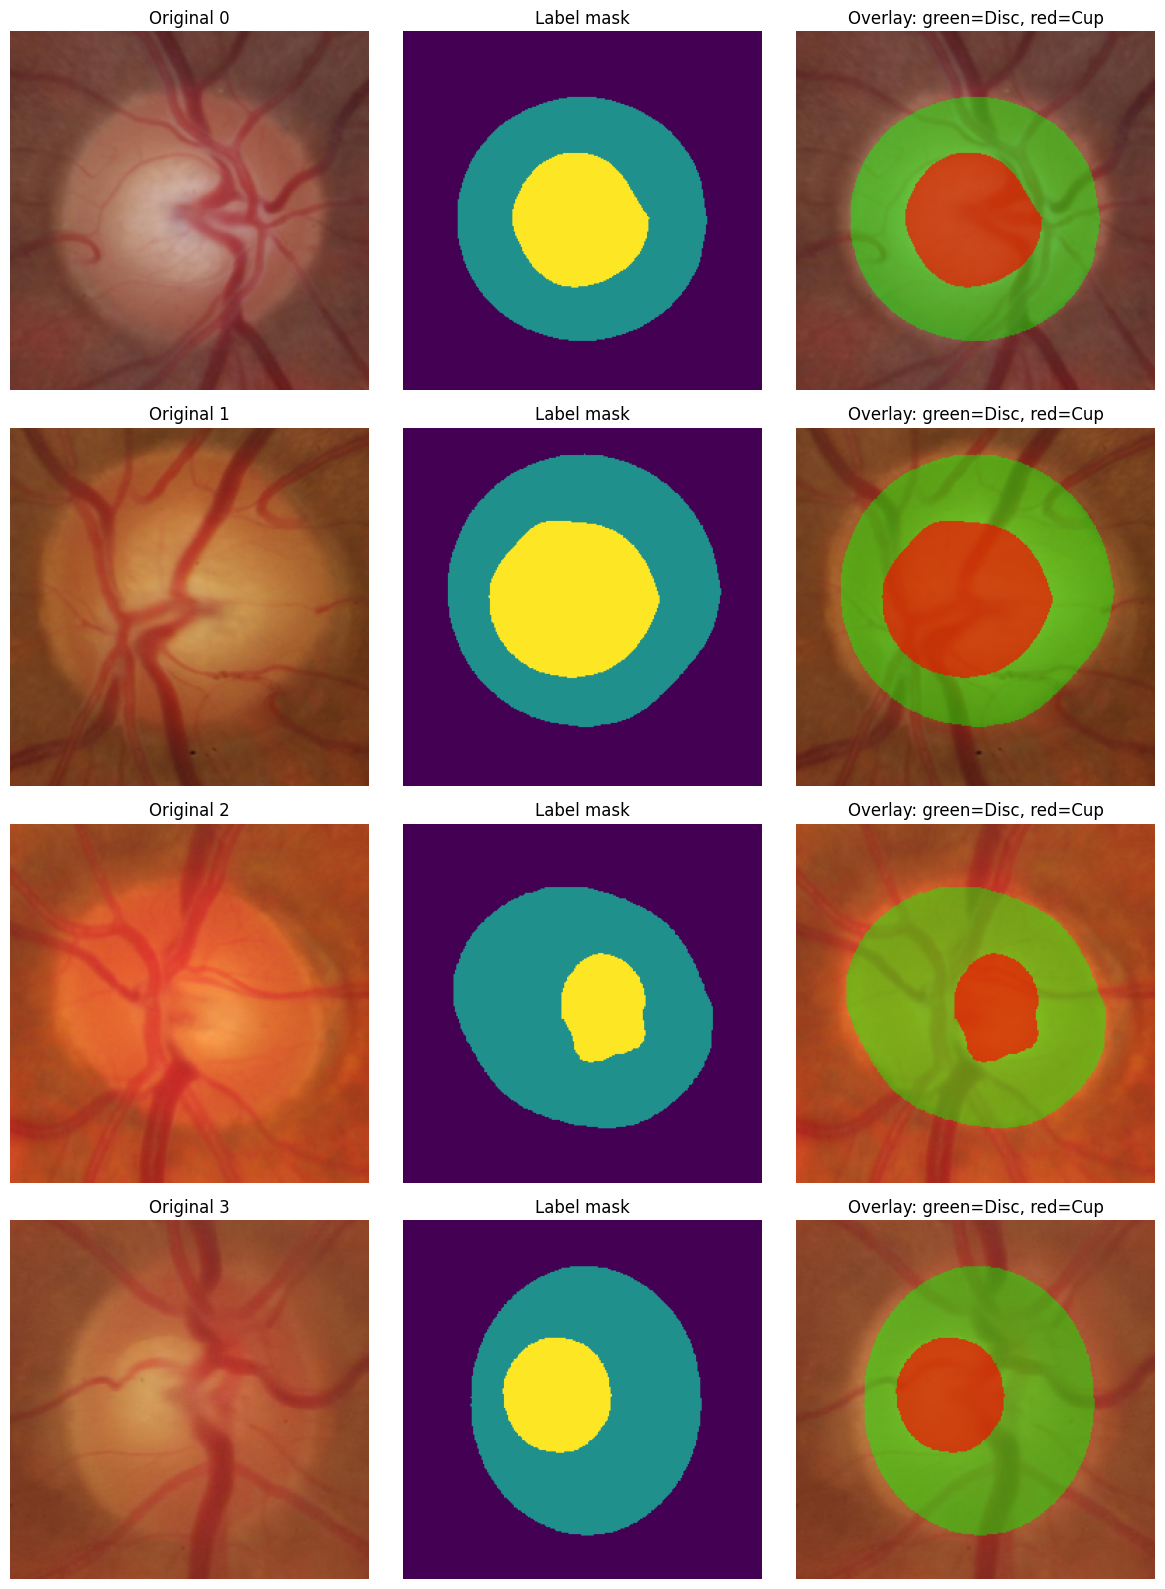

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for i in range(4):
    image, mask = train_ds[i]

    image = image.permute(1, 2, 0).numpy()
    mask = mask.numpy()

    # Disc đầy đủ gồm Disc-only (1) và Cup (2)
    disc = (mask == 1) | (mask == 2)
    cup = mask == 2

    overlay = image.copy()

    # Tô màu vùng Disc bằng xanh lá, Cup bằng đỏ
    overlay[disc] = (
        0.55 * overlay[disc]
        + 0.45 * np.array([0.0, 1.0, 0.0])
    )
    overlay[cup] = (
        0.35 * overlay[cup]
        + 0.65 * np.array([1.0, 0.0, 0.0])
    )

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Original {i}")

    axes[i, 1].imshow(mask, vmin=0, vmax=2, cmap="viridis")
    axes[i, 1].set_title("Label mask")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Overlay: green=Disc, red=Cup")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


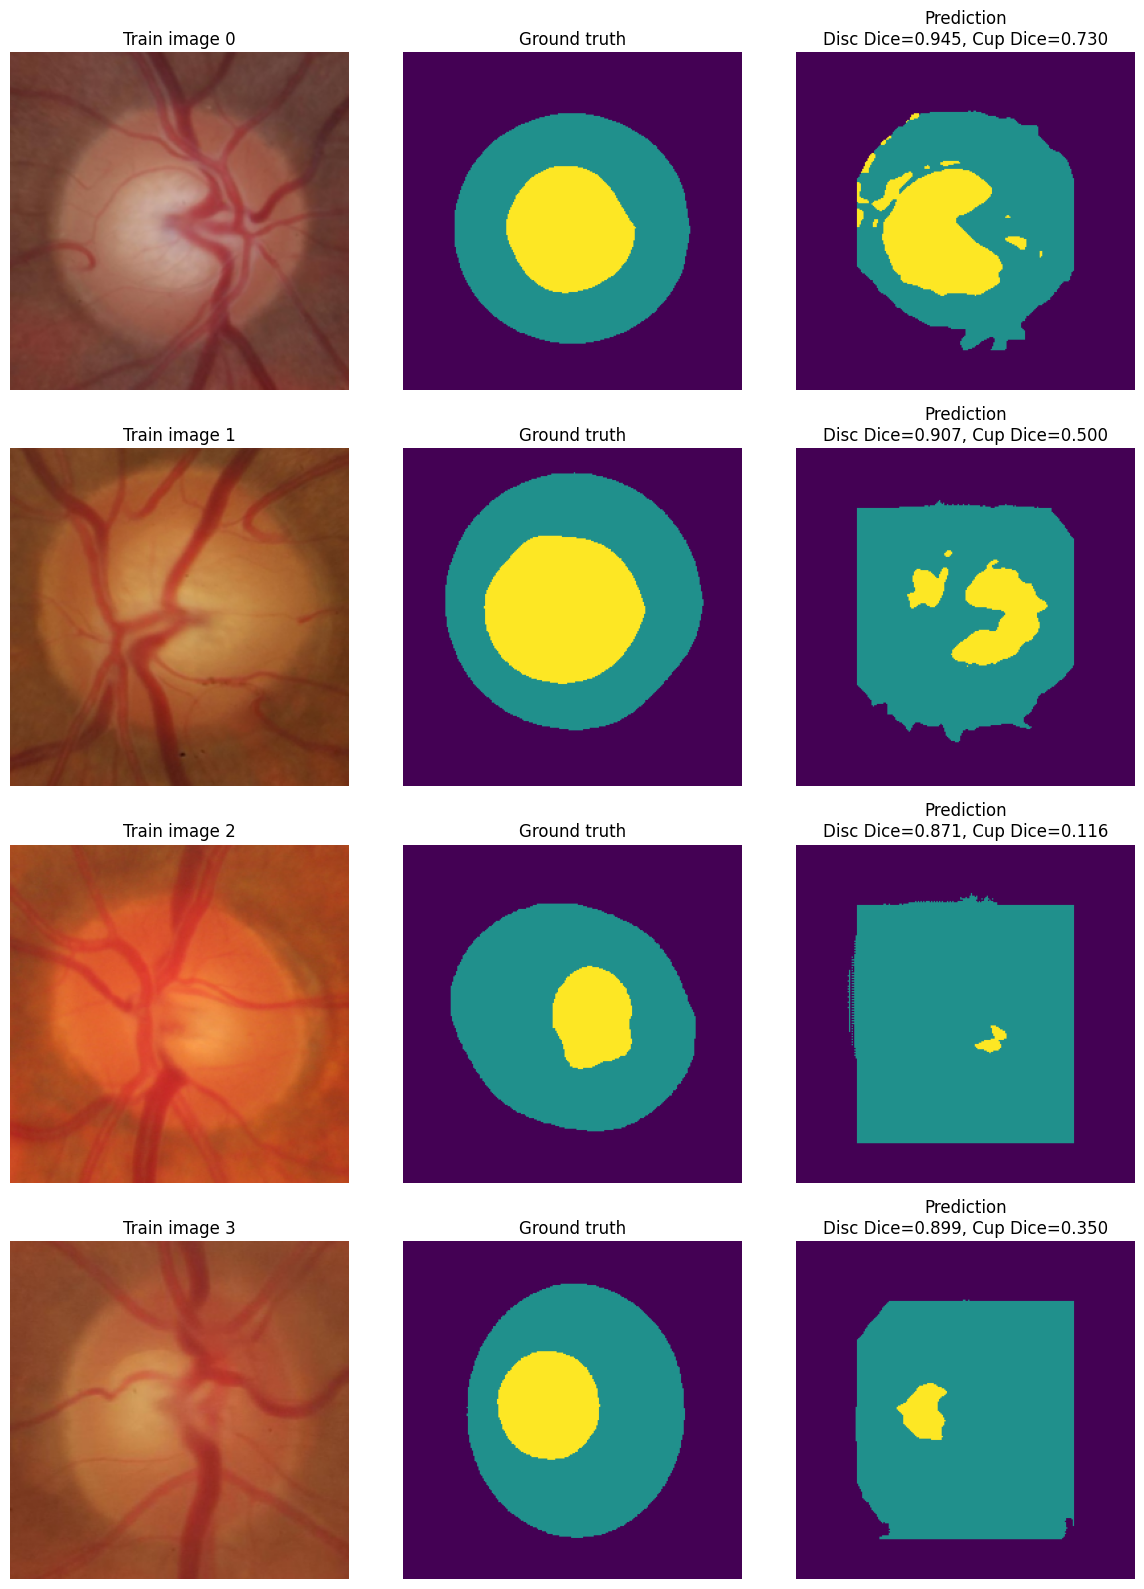

Mean Disc Dice (4 train images): 0.9055
Mean Cup Dice (4 train images): 0.4241


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import torch

model.eval()

def binary_dice(pred_mask, true_mask):
    pred_mask = pred_mask.bool()
    true_mask = true_mask.bool()

    intersection = (pred_mask & true_mask).sum().item()
    denominator = pred_mask.sum().item() + true_mask.sum().item()

    if denominator == 0:
        return 1.0

    return 2.0 * intersection / denominator

fig, axes = plt.subplots(4, 3, figsize=(12, 16))
disc_dices = []
cup_dices = []

with torch.no_grad():
    for i in range(4):
        image, true_mask = train_ds[i]

        logits = model(image.unsqueeze(0).to(DEVICE))
        pred_mask = torch.argmax(logits, dim=1)[0].cpu()

        # Disc đầy đủ gồm lớp Disc-only (1) và Cup (2)
        true_disc = (true_mask == 1) | (true_mask == 2)
        pred_disc = (pred_mask == 1) | (pred_mask == 2)

        true_cup = true_mask == 2
        pred_cup = pred_mask == 2

        d_disc = binary_dice(pred_disc, true_disc)
        d_cup = binary_dice(pred_cup, true_cup)

        disc_dices.append(d_disc)
        cup_dices.append(d_cup)

        image_np = image.permute(1, 2, 0).numpy()
        true_np = true_mask.numpy()
        pred_np = pred_mask.numpy()

        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title(f"Train image {i}")

        axes[i, 1].imshow(true_np, vmin=0, vmax=2, cmap="viridis")
        axes[i, 1].set_title("Ground truth")

        axes[i, 2].imshow(pred_np, vmin=0, vmax=2, cmap="viridis")
        axes[i, 2].set_title(
            f"Prediction\nDisc Dice={d_disc:.3f}, Cup Dice={d_cup:.3f}"
        )

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Mean Disc Dice (4 train images): {np.mean(disc_dices):.4f}")
print(f"Mean Cup Dice (4 train images): {np.mean(cup_dices):.4f}")


In [ ]:

import numpy as np
import torch

model.eval()

with torch.no_grad():
    for i in range(4):
        image, true_mask = train_ds[i]

        logits = model(image.unsqueeze(0).to(DEVICE))
        pred = torch.argmax(logits, dim=1)[0].cpu().numpy()
        true = true_mask.numpy()

        # Gộp Disc-only và Cup để tính toàn bộ Disc
        true_disc = np.isin(true, [1, 2])
        pred_disc = np.isin(pred, [1, 2])

        true_cup = true == 2
        pred_cup = pred == 2

        print(f"\nTrain image {i}")
        print(f"Ground-truth Disc area: {true_disc.mean():.3f}")
        print(f"Predicted Disc area:    {pred_disc.mean():.3f}")
        print(f"Ground-truth Cup area:  {true_cup.mean():.3f}")
        print(f"Predicted Cup area:     {pred_cup.mean():.3f}")
        print(
            "Predicted pixel fractions:",
            {
                "background": round((pred == 0).mean(), 3),
                "disc_only": round((pred == 1).mean(), 3),
                "cup": round((pred == 2).mean(), 3),
            }
        )



Train image 0
Ground-truth Disc area: 0.373
Predicted Disc area:    0.354
Ground-truth Cup area:  0.107
Predicted Cup area:     0.103
Predicted pixel fractions: {'background': np.float64(0.646), 'disc_only': np.float64(0.251), 'cup': np.float64(0.103)}

Train image 1
Ground-truth Disc area: 0.446
Predicted Disc area:    0.390
Ground-truth Cup area:  0.159
Predicted Cup area:     0.056
Predicted pixel fractions: {'background': np.float64(0.61), 'disc_only': np.float64(0.334), 'cup': np.float64(0.056)}

Train image 2
Ground-truth Disc area: 0.375
Predicted Disc area:    0.458
Ground-truth Cup area:  0.056
Predicted Cup area:     0.003
Predicted pixel fractions: {'background': np.float64(0.542), 'disc_only': np.float64(0.455), 'cup': np.float64(0.003)}

Train image 3
Ground-truth Disc area: 0.379
Predicted Disc area:    0.436
Ground-truth Cup area:  0.076
Predicted Cup area:     0.016
Predicted pixel fractions: {'background': np.float64(0.564), 'disc_only': np.float64(0.42), 'cup': np.fl

In [ ]:

import numpy as np
from collections import Counter

pixel_counts = Counter()
image_area_stats = []

for i in range(len(train_ds)):
    _, mask = train_ds[i]
    mask = mask.numpy()

    counts = {
        "background": np.sum(mask == 0),
        "disc_only": np.sum(mask == 1),
        "cup": np.sum(mask == 2),
    }

    pixel_counts.update(counts)

    image_area_stats.append([
        counts["background"] / mask.size,
        counts["disc_only"] / mask.size,
        counts["cup"] / mask.size,
    ])

stats = np.asarray(image_area_stats)

print("Number of training images:", len(train_ds))
print("\nPixel distribution over the entire training set:")

total_pixels = sum(pixel_counts.values())
for name, count in pixel_counts.items():
    print(f"{name}: {count / total_pixels:.4f}")

print("\nPer-image area fraction:")
print(f"Background: mean={stats[:, 0].mean():.4f}, "
      f"min={stats[:, 0].min():.4f}, max={stats[:, 0].max():.4f}")
print(f"Disc-only:  mean={stats[:, 1].mean():.4f}, "
      f"min={stats[:, 1].min():.4f}, max={stats[:, 1].max():.4f}")
print(f"Cup:        mean={stats[:, 2].mean():.4f}, "
      f"min={stats[:, 2].min():.4f}, max={stats[:, 2].max():.4f}")


Number of training images: 271

Pixel distribution over the entire training set:
background: 0.5937
disc_only: 0.3005
cup: 0.1058

Per-image area fraction:
Background: mean=0.5937, min=0.4034, max=0.7400
Disc-only:  mean=0.3005, min=0.0477, max=0.4566
Cup:        mean=0.1058, min=0.0023, max=0.3494


In [ ]:

import torch
import torch.nn as nn

# Tăng trọng số cho Cup (class 2)
class_weights = torch.tensor(
    [1.0, 1.0, 2.0],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

# Khởi tạo optimizer mới với learning rate thấp hơn
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=3e-4
)

print("Loss: Weighted CrossEntropyLoss")
print("Class weights:", class_weights.tolist())
print("Learning rate:", 3e-4)
print("Device:", DEVICE)


Loss: Weighted CrossEntropyLoss
Class weights: [1.0, 1.0, 2.0]
Learning rate: 0.0003
Device: cuda


In [ ]:

from pathlib import Path
import torch

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
checkpoint_path = OUTPUT_DIR / "best_unet.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

# Giữ nguyên Weighted CrossEntropyLoss và optimizer mới
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

print("Loaded checkpoint from baseline training")
print("Baseline best epoch:", checkpoint["epoch"])
print("Baseline best validation loss:", checkpoint["best_val_loss"])
print("New learning rate:", optimizer.param_groups[0]["lr"])
print("New loss:", type(criterion).__name__)


Loaded checkpoint from baseline training
Baseline best epoch: 29
Baseline best validation loss: 0.4211825377800885
New learning rate: 0.0003
New loss: CrossEntropyLoss


Loss weights: [1.0, 1.0, 2.0]
Learning rate: 0.0003
Epoch 01/15 | Train loss=0.4754 | Val loss=0.4766 | Val Disc Dice=0.6436 | Val Cup Dice=0.4265
  -> Saved best weighted checkpoint
Epoch 02/15 | Train loss=0.4684 | Val loss=0.4859 | Val Disc Dice=0.6190 | Val Cup Dice=0.4386
Epoch 03/15 | Train loss=0.4702 | Val loss=0.4758 | Val Disc Dice=0.6506 | Val Cup Dice=0.4248
  -> Saved best weighted checkpoint
Epoch 04/15 | Train loss=0.4693 | Val loss=0.4780 | Val Disc Dice=0.6478 | Val Cup Dice=0.4303
Epoch 05/15 | Train loss=0.4663 | Val loss=0.4724 | Val Disc Dice=0.6704 | Val Cup Dice=0.4071
  -> Saved best weighted checkpoint
Epoch 06/15 | Train loss=0.4691 | Val loss=0.4734 | Val Disc Dice=0.6483 | Val Cup Dice=0.4268
Epoch 07/15 | Train loss=0.4651 | Val loss=0.4720 | Val Disc Dice=0.6595 | Val Cup Dice=0.4149
  -> Saved best weighted checkpoint
Epoch 08/15 | Train loss=0.4666 | Val loss=0.4752 | Val Disc Dice=0.6551 | Val Cup Dice=0.4330
Epoch 09/15 | Train loss=0.4655 | Val loss=0

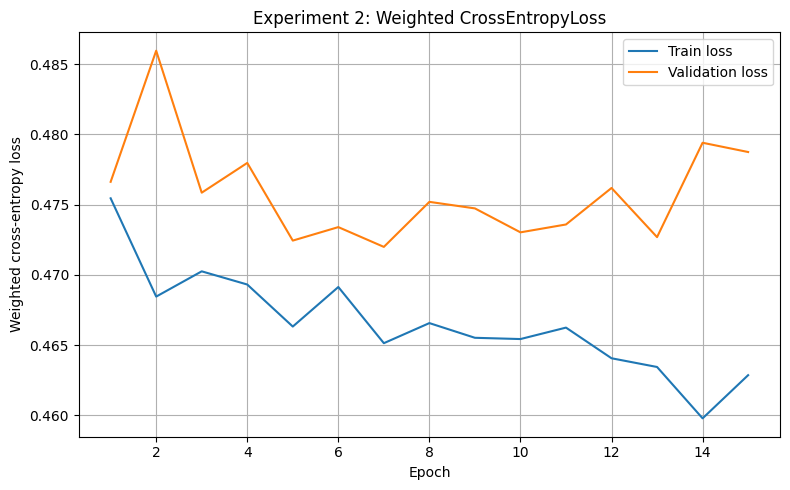


Best weighted validation loss: 0.4720
Elapsed: 1.5 minutes
Saved to: /content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results/weighted_cup_experiment


In [ ]:

import csv
import time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import torch

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
EXP2_DIR = OUTPUT_DIR / "weighted_cup_experiment"
EXP2_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS_EXP2 = 15
best_val_loss_exp2 = float("inf")
history_exp2 = []

print("Loss weights:", criterion.weight.detach().cpu().tolist())
print("Learning rate:", optimizer.param_groups[0]["lr"])

start_time = time.time()

for epoch in range(1, EPOCHS_EXP2 + 1):
    train_loss, train_disc, train_cup = run_epoch(
        train_loader, training=True
    )

    val_loss, val_disc, val_cup = run_epoch(
        val_loader, training=False
    )

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_disc_dice": train_disc,
        "train_cup_dice": train_cup,
        "val_disc_dice": val_disc,
        "val_cup_dice": val_cup,
    }
    history_exp2.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS_EXP2} | "
        f"Train loss={train_loss:.4f} | "
        f"Val loss={val_loss:.4f} | "
        f"Val Disc Dice={val_disc:.4f} | "
        f"Val Cup Dice={val_cup:.4f}"
    )

    if np.isfinite(val_loss) and val_loss < best_val_loss_exp2:
        best_val_loss_exp2 = val_loss

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss_exp2,
                "class_weights": criterion.weight.detach().cpu(),
                "learning_rate": optimizer.param_groups[0]["lr"],
            },
            EXP2_DIR / "best_unet_weighted.pt",
        )
        print("  -> Saved best weighted checkpoint")

# Lưu lịch sử huấn luyện
with open(
    EXP2_DIR / "training_history_weighted.csv",
    "w",
    newline="",
    encoding="utf-8-sig",
) as f:
    writer = csv.DictWriter(
        f, fieldnames=history_exp2[0].keys()
    )
    writer.writeheader()
    writer.writerows(history_exp2)

# Vẽ loss curve
epochs = [r["epoch"] for r in history_exp2]

plt.figure(figsize=(8, 5))
plt.plot(
    epochs, [r["train_loss"] for r in history_exp2],
    label="Train loss"
)
plt.plot(
    epochs, [r["val_loss"] for r in history_exp2],
    label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy loss")
plt.title("Experiment 2: Weighted CrossEntropyLoss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(EXP2_DIR / "loss_curve_weighted.png", dpi=150)
plt.show()
plt.close()

print(f"\nBest weighted validation loss: {best_val_loss_exp2:.4f}")
print(f"Elapsed: {(time.time() - start_time) / 60:.1f} minutes")
print(f"Saved to: {EXP2_DIR}")


In [ ]:

import numpy as np
import torch
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)

baseline_path = OUTPUT_DIR / "best_unet.pt"
weighted_path = (
    OUTPUT_DIR / "weighted_cup_experiment"
    / "best_unet_weighted.pt"
)

def evaluate_checkpoint(checkpoint_path, name):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    disc_scores = []
    cup_scores = []

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(DEVICE)
            predictions = model(images).argmax(dim=1).cpu()

            for i in range(len(masks)):
                pred = predictions[i]
                true = masks[i]

                # Dice của toàn bộ Disc = Disc-only + Cup
                pred_disc = (pred == 1) | (pred == 2)
                true_disc = (true == 1) | (true == 2)

                pred_cup = pred == 2
                true_cup = true == 2

                disc_scores.append(
                    binary_dice(pred_disc, true_disc)
                )
                cup_scores.append(
                    binary_dice(pred_cup, true_cup)
                )

    result = {
        "model": name,
        "checkpoint_epoch": checkpoint["epoch"],
        "checkpoint_val_loss": checkpoint["best_val_loss"],
        "disc_dice": float(np.mean(disc_scores)),
        "cup_dice": float(np.mean(cup_scores)),
    }
    return result


baseline_result = evaluate_checkpoint(
    baseline_path, "Baseline"
)
weighted_result = evaluate_checkpoint(
    weighted_path, "Weighted CrossEntropy"
)

for result in [baseline_result, weighted_result]:
    print("\n", result["model"])
    print("Checkpoint epoch:", result["checkpoint_epoch"])
    print("Checkpoint validation loss:", result["checkpoint_val_loss"])
    print("Validation Disc Dice:", round(result["disc_dice"], 4))
    print("Validation Cup Dice:", round(result["cup_dice"], 4))

print("\nChange in Cup Dice:",
      round(weighted_result["cup_dice"] - baseline_result["cup_dice"], 4))



 Baseline
Checkpoint epoch: 29
Checkpoint validation loss: 0.4211825377800885
Validation Disc Dice: 0.8276
Validation Cup Dice: 0.3047

 Weighted CrossEntropy
Checkpoint epoch: 7
Checkpoint validation loss: 0.4719842304201687
Validation Disc Dice: 0.8394
Validation Cup Dice: 0.4149

Change in Cup Dice: 0.1102


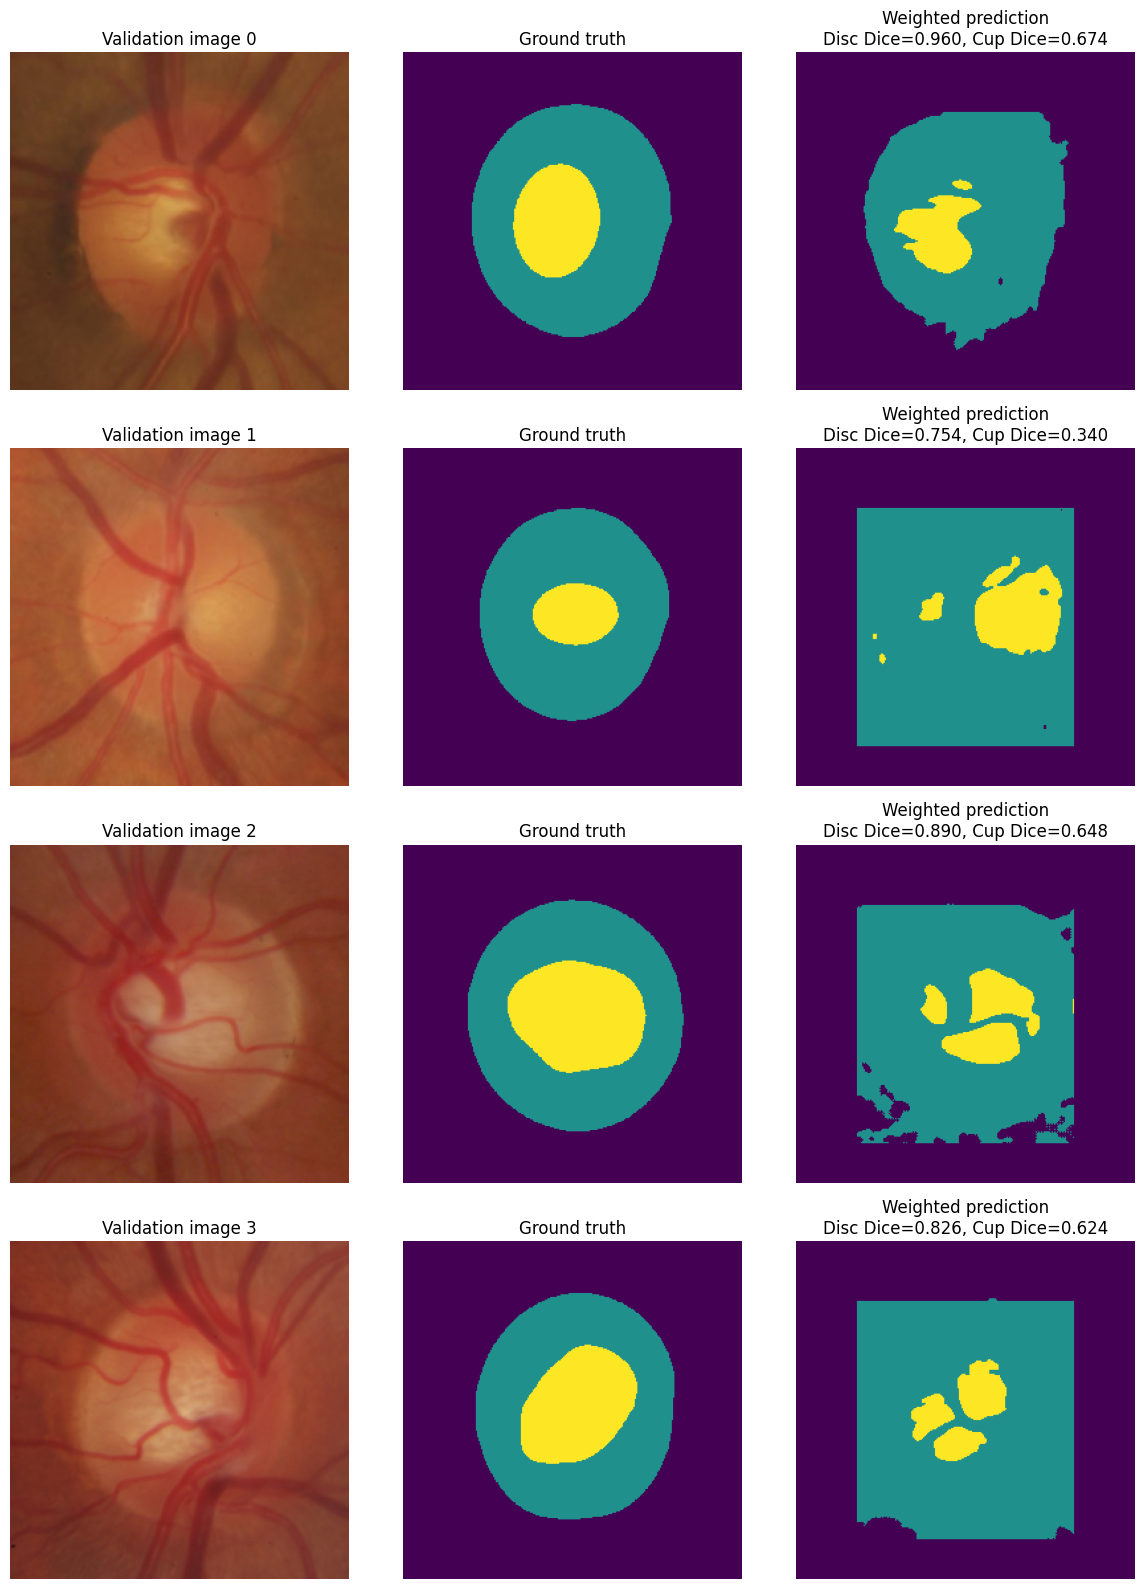

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import torch
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
weighted_path = (
    OUTPUT_DIR / "weighted_cup_experiment"
    / "best_unet_weighted.pt"
)

checkpoint = torch.load(
    weighted_path,
    map_location=DEVICE,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

with torch.no_grad():
    for i in range(4):
        image, true_mask = val_ds[i]
        logits = model(image.unsqueeze(0).to(DEVICE))
        pred = torch.argmax(logits, dim=1)[0].cpu()

        true_disc = (true_mask == 1) | (true_mask == 2)
        pred_disc = (pred == 1) | (pred == 2)

        true_cup = true_mask == 2
        pred_cup = pred == 2

        d_disc = binary_dice(pred_disc, true_disc)
        d_cup = binary_dice(pred_cup, true_cup)

        image_np = image.permute(1, 2, 0).numpy()

        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title(f"Validation image {i}")

        axes[i, 1].imshow(
            true_mask.numpy(), vmin=0, vmax=2, cmap="viridis"
        )
        axes[i, 1].set_title("Ground truth")

        axes[i, 2].imshow(
            pred.numpy(), vmin=0, vmax=2, cmap="viridis"
        )
        axes[i, 2].set_title(
            f"Weighted prediction\nDisc Dice={d_disc:.3f}, "
            f"Cup Dice={d_cup:.3f}"
        )

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import torch

model.eval()

with torch.no_grad():
    for i in range(4):
        image, true_mask = val_ds[i]
        logits = model(image.unsqueeze(0).to(DEVICE))
        pred = torch.argmax(logits, dim=1)[0].cpu().numpy()
        img = image.permute(1, 2, 0).numpy()

        print(f"\nValidation image {i}")
        print("Image shape:", img.shape)
        print("Image min/max:", float(img.min()), float(img.max()))
        print("Corner pixel values:")
        print("Top-left:", img[0, 0].round(3))
        print("Top-right:", img[0, -1].round(3))
        print("Bottom-left:", img[-1, 0].round(3))
        print("Bottom-right:", img[-1, -1].round(3))

        print("Prediction fractions:")
        for label, name in [(0, "background"), (1, "disc_only"), (2, "cup")]:
            print(f"  {name}: {(pred == label).mean():.4f}")



Validation image 0
Image shape: (256, 256, 3)
Image min/max: 0.07450980693101883 0.8274509906768799
Corner pixel values:
Top-left: [0.388 0.212 0.122]
Top-right: [0.49  0.247 0.145]
Bottom-left: [0.365 0.208 0.11 ]
Bottom-right: [0.482 0.271 0.137]
Prediction fractions:
  background: 0.6828
  disc_only: 0.2800
  cup: 0.0372

Validation image 1
Image shape: (256, 256, 3)
Image min/max: 0.10588235408067703 0.8627451062202454
Corner pixel values:
Top-left: [0.686 0.318 0.184]
Top-right: [0.525 0.263 0.149]
Bottom-left: [0.608 0.282 0.157]
Bottom-right: [0.584 0.247 0.149]
Prediction fractions:
  background: 0.5497
  disc_only: 0.3923
  cup: 0.0580

Validation image 2
Image shape: (256, 256, 3)
Image min/max: 0.05882352963089943 0.7647058963775635
Corner pixel values:
Top-left: [0.455 0.212 0.157]
Top-right: [0.49  0.224 0.149]
Bottom-left: [0.447 0.208 0.133]
Bottom-right: [0.494 0.216 0.129]
Prediction fractions:
  background: 0.5809
  disc_only: 0.3684
  cup: 0.0507

Validation image 3

In [ ]:

import numpy as np
import torch

def get_bbox(mask):
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return None
    return {
        "x_min": int(xs.min()),
        "x_max": int(xs.max()),
        "y_min": int(ys.min()),
        "y_max": int(ys.max()),
        "width": int(xs.max() - xs.min() + 1),
        "height": int(ys.max() - ys.min() + 1),
    }

model.eval()

with torch.no_grad():
    for i in range(4):
        image, true_mask = val_ds[i]
        pred = model(
            image.unsqueeze(0).to(DEVICE)
        ).argmax(dim=1)[0].cpu().numpy()

        true = true_mask.numpy()

        true_disc = np.isin(true, [1, 2])
        pred_disc = np.isin(pred, [1, 2])

        print(f"\nValidation image {i}")
        print("Ground-truth Disc bbox:", get_bbox(true_disc))
        print("Predicted Disc bbox:   ", get_bbox(pred_disc))



Validation image 0
Ground-truth Disc bbox: {'x_min': 52, 'x_max': 202, 'y_min': 40, 'y_max': 215, 'width': 151, 'height': 176}
Predicted Disc bbox:    {'x_min': 51, 'x_max': 205, 'y_min': 46, 'y_max': 225, 'width': 155, 'height': 180}

Validation image 1
Ground-truth Disc bbox: {'x_min': 58, 'x_max': 200, 'y_min': 46, 'y_max': 206, 'width': 143, 'height': 161}
Predicted Disc bbox:    {'x_min': 46, 'x_max': 209, 'y_min': 46, 'y_max': 225, 'width': 164, 'height': 180}

Validation image 2
Ground-truth Disc bbox: {'x_min': 49, 'x_max': 211, 'y_min': 42, 'y_max': 216, 'width': 163, 'height': 175}
Predicted Disc bbox:    {'x_min': 46, 'x_max': 209, 'y_min': 45, 'y_max': 225, 'width': 164, 'height': 181}

Validation image 3
Ground-truth Disc bbox: {'x_min': 55, 'x_max': 204, 'y_min': 40, 'y_max': 210, 'width': 150, 'height': 171}
Predicted Disc bbox:    {'x_min': 46, 'x_max': 209, 'y_min': 44, 'y_max': 225, 'width': 164, 'height': 182}


In [ ]:

import numpy as np
import torch

model.eval()

with torch.no_grad():
    for i in range(4):
        image, true_mask = val_ds[i]
        pred = model(
            image.unsqueeze(0).to(DEVICE)
        ).argmax(dim=1)[0].cpu().numpy()

        true = true_mask.numpy()

        true_background = true == 0
        true_disc = np.isin(true, [1, 2])
        pred_disc = np.isin(pred, [1, 2])

        # Pixel nền bị dự đoán nhầm thành Disc
        false_disc = true_background & pred_disc

        # Tỷ lệ nền bị nhầm thành Disc
        false_disc_rate = false_disc.sum() / max(
            true_background.sum(), 1
        )

        # Tỷ lệ pixel Disc dự đoán đúng
        disc_recall = (
            (true_disc & pred_disc).sum()
            / max(true_disc.sum(), 1)
        )

        print(f"\nValidation image {i}")
        print("Background pixels:", int(true_background.sum()))
        print("Background predicted as Disc:", int(false_disc.sum()))
        print(f"Background false-positive rate: {false_disc_rate:.4f}")
        print(f"Disc pixel recall: {disc_recall:.4f}")



Validation image 0
Background pixels: 44723
Background predicted as Disc: 817
Background false-positive rate: 0.0183
Disc pixel recall: 0.9595

Validation image 1
Background pixels: 47683
Background predicted as Disc: 11660
Background false-positive rate: 0.2445
Disc pixel recall: 1.0000

Validation image 2
Background pixels: 43182
Background predicted as Disc: 5286
Background false-positive rate: 0.1224
Disc pixel recall: 0.9921

Validation image 3
Background pixels: 44881
Background predicted as Disc: 8401
Background false-positive rate: 0.1872
Disc pixel recall: 0.9894


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class CombinedSegmentationLoss(nn.Module):
    def __init__(self, class_weights, dice_weight=1.0, eps=1e-6):
        super().__init__()
        self.register_buffer("class_weights", class_weights.clone())
        self.dice_weight = dice_weight
        self.eps = eps

    def forward(self, logits, target):
        ce = F.cross_entropy(
            logits,
            target,
            weight=self.class_weights
        )

        probs = torch.softmax(logits, dim=1)
        target_onehot = F.one_hot(
            target, num_classes=3
        ).permute(0, 3, 1, 2).float()

        # Bỏ nền khỏi Dice loss; tập trung vào hai vùng giải phẫu
        probs_fg = probs[:, 1:, :, :]
        target_fg = target_onehot[:, 1:, :, :]

        dims = (0, 2, 3)
        intersection = (probs_fg * target_fg).sum(dim=dims)
        denominator = probs_fg.sum(dim=dims) + target_fg.sum(dim=dims)

        dice_per_class = (
            2 * intersection + self.eps
        ) / (denominator + self.eps)

        dice_loss = 1 - dice_per_class.mean()

        return ce + self.dice_weight * dice_loss


# Khôi phục checkpoint Weighted đã chọn
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
weighted_path = (
    OUTPUT_DIR / "weighted_cup_experiment"
    / "best_unet_weighted.pt"
)

checkpoint = torch.load(
    weighted_path,
    map_location=DEVICE,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])

class_weights = torch.tensor(
    [1.0, 1.0, 2.0],
    dtype=torch.float32,
    device=DEVICE
)

criterion = CombinedSegmentationLoss(
    class_weights=class_weights,
    dice_weight=1.0
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

print("Loss: Weighted CrossEntropy + Dice")
print("Class weights:", class_weights.tolist())
print("Dice loss weight:", criterion.dice_weight)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Checkpoint epoch:", checkpoint["epoch"])


Loss: Weighted CrossEntropy + Dice
Class weights: [1.0, 1.0, 2.0]
Dice loss weight: 1.0
Learning rate: 0.0001
Checkpoint epoch: 7


Epoch 01/15 | Train loss=0.9498 | Val loss=0.9840 | Val Disc Dice=0.6839 | Val Cup Dice=0.4222
  -> Saved best combined-loss checkpoint
Epoch 02/15 | Train loss=0.9422 | Val loss=0.9839 | Val Disc Dice=0.6888 | Val Cup Dice=0.4217
  -> Saved best combined-loss checkpoint
Epoch 03/15 | Train loss=0.9374 | Val loss=0.9863 | Val Disc Dice=0.6995 | Val Cup Dice=0.4124
Epoch 04/15 | Train loss=0.9363 | Val loss=0.9783 | Val Disc Dice=0.6841 | Val Cup Dice=0.4188
  -> Saved best combined-loss checkpoint
Epoch 05/15 | Train loss=0.9375 | Val loss=0.9784 | Val Disc Dice=0.6881 | Val Cup Dice=0.4193
Epoch 06/15 | Train loss=0.9331 | Val loss=0.9709 | Val Disc Dice=0.6999 | Val Cup Dice=0.4050
  -> Saved best combined-loss checkpoint
Epoch 07/15 | Train loss=0.9294 | Val loss=0.9780 | Val Disc Dice=0.6826 | Val Cup Dice=0.4261
Epoch 08/15 | Train loss=0.9256 | Val loss=0.9713 | Val Disc Dice=0.7024 | Val Cup Dice=0.3953
Epoch 09/15 | Train loss=0.9252 | Val loss=0.9744 | Val Disc Dice=0.7037 | V

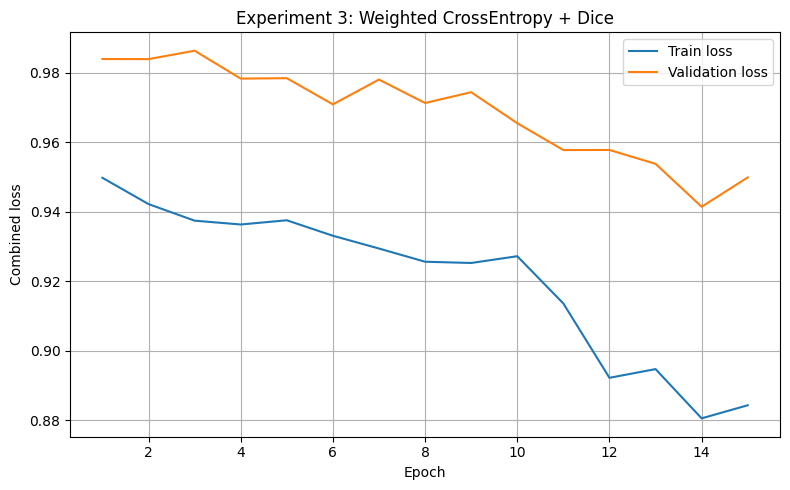


Best combined validation loss: 0.9414
Elapsed: 1.5 minutes
Saved to: /content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results/combined_loss_experiment


In [ ]:

import csv
import time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import torch

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
EXP3_DIR = OUTPUT_DIR / "combined_loss_experiment"
EXP3_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS_EXP3 = 15
best_val_loss_exp3 = float("inf")
history_exp3 = []

start_time = time.time()

for epoch in range(1, EPOCHS_EXP3 + 1):
    train_loss, train_disc, train_cup = run_epoch(
        train_loader, training=True
    )

    val_loss, val_disc, val_cup = run_epoch(
        val_loader, training=False
    )

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_disc_dice": train_disc,
        "train_cup_dice": train_cup,
        "val_disc_dice": val_disc,
        "val_cup_dice": val_cup,
    }
    history_exp3.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS_EXP3} | "
        f"Train loss={train_loss:.4f} | "
        f"Val loss={val_loss:.4f} | "
        f"Val Disc Dice={val_disc:.4f} | "
        f"Val Cup Dice={val_cup:.4f}"
    )

    if np.isfinite(val_loss) and val_loss < best_val_loss_exp3:
        best_val_loss_exp3 = val_loss

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss_exp3,
                "class_weights": criterion.class_weights.detach().cpu(),
                "dice_weight": criterion.dice_weight,
                "learning_rate": optimizer.param_groups[0]["lr"],
            },
            EXP3_DIR / "best_unet_combined.pt",
        )
        print("  -> Saved best combined-loss checkpoint")

with open(
    EXP3_DIR / "training_history_combined.csv",
    "w",
    newline="",
    encoding="utf-8-sig",
) as f:
    writer = csv.DictWriter(
        f, fieldnames=history_exp3[0].keys()
    )
    writer.writeheader()
    writer.writerows(history_exp3)

epochs = [r["epoch"] for r in history_exp3]

plt.figure(figsize=(8, 5))
plt.plot(
    epochs, [r["train_loss"] for r in history_exp3],
    label="Train loss"
)
plt.plot(
    epochs, [r["val_loss"] for r in history_exp3],
    label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("Combined loss")
plt.title("Experiment 3: Weighted CrossEntropy + Dice")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(EXP3_DIR / "loss_curve_combined.png", dpi=150)
plt.show()
plt.close()

print(f"\nBest combined validation loss: {best_val_loss_exp3:.4f}")
print(f"Elapsed: {(time.time() - start_time) / 60:.1f} minutes")
print(f"Saved to: {EXP3_DIR}")


In [ ]:

import csv
import numpy as np
import torch
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)

checkpoints = {
    "Baseline": OUTPUT_DIR / "best_unet.pt",
    "Weighted_CE": (
        OUTPUT_DIR / "weighted_cup_experiment"
        / "best_unet_weighted.pt"
    ),
    "Weighted_CE_Dice": (
        OUTPUT_DIR / "combined_loss_experiment"
        / "best_unet_combined.pt"
    ),
}

def calculate_binary_dice(pred_mask, true_mask):
    intersection = (pred_mask & true_mask).sum().item()
    denominator = pred_mask.sum().item() + true_mask.sum().item()
    if denominator == 0:
        return 1.0
    return 2.0 * intersection / denominator

results = []

for model_name, checkpoint_path in checkpoints.items():
    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint: {checkpoint_path}"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    disc_scores = []
    cup_scores = []

    with torch.no_grad():
        for images, masks in val_loader:
            predictions = model(images.to(DEVICE)).argmax(dim=1).cpu()

            for i in range(len(masks)):
                pred = predictions[i]
                true = masks[i]

                # Toàn bộ Disc bao gồm lớp 1 và lớp 2
                pred_disc = (pred == 1) | (pred == 2)
                true_disc = (true == 1) | (true == 2)

                pred_cup = pred == 2
                true_cup = true == 2

                disc_scores.append(
                    calculate_binary_dice(pred_disc, true_disc)
                )
                cup_scores.append(
                    calculate_binary_dice(pred_cup, true_cup)
                )

    result = {
        "model": model_name,
        "checkpoint_epoch": int(checkpoint["epoch"]),
        "checkpoint_val_loss": float(checkpoint["best_val_loss"]),
        "validation_disc_dice": float(np.mean(disc_scores)),
        "validation_cup_dice": float(np.mean(cup_scores)),
        "validation_mean_dice": float(
            (np.mean(disc_scores) + np.mean(cup_scores)) / 2
        ),
    }
    results.append(result)

    print(f"\n{model_name}")
    for key, value in result.items():
        print(f"  {key}: {value}")

# Chọn mô hình theo Mean Dice trên validation
# (trung bình Disc Dice và Cup Dice)
best_result = max(
    results, key=lambda r: r["validation_mean_dice"]
)

csv_path = OUTPUT_DIR / "validation_model_comparison.csv"
with open(csv_path, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)

print("\nSelected checkpoint:", best_result["model"])
print("Selection criterion: highest validation mean Dice")
print("Comparison saved to:", csv_path)



Baseline
  model: Baseline
  checkpoint_epoch: 29
  checkpoint_val_loss: 0.4211825377800885
  validation_disc_dice: 0.8276123159051008
  validation_cup_dice: 0.3046721292603377
  validation_mean_dice: 0.5661422225827193

Weighted_CE
  model: Weighted_CE
  checkpoint_epoch: 7
  checkpoint_val_loss: 0.4719842304201687
  validation_disc_dice: 0.8393803432904343
  validation_cup_dice: 0.4148673446069683
  validation_mean_dice: 0.6271238439487012

Weighted_CE_Dice
  model: Weighted_CE_Dice
  checkpoint_epoch: 14
  checkpoint_val_loss: 0.9414242365780998
  validation_disc_dice: 0.8787061503178015
  validation_cup_dice: 0.4666761727594775
  validation_mean_dice: 0.6726911615386395

Selected checkpoint: Weighted_CE_Dice
Selection criterion: highest validation mean Dice
Comparison saved to: /content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results/validation_model_comparison.csv


In [ ]:

import csv
import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)
EXP3_DIR = OUTPUT_DIR / "combined_loss_experiment"

checkpoint_path = EXP3_DIR / "best_unet_combined.pt"
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

disc_scores = []
cup_scores = []
test_rows = []

with torch.no_grad():
    for batch_images, batch_masks in test_loader:
        predictions = model(
            batch_images.to(DEVICE)
        ).argmax(dim=1).cpu()

        for i in range(len(batch_masks)):
            pred = predictions[i]
            true = batch_masks[i]

            pred_disc = (pred == 1) | (pred == 2)
            true_disc = (true == 1) | (true == 2)
            pred_cup = pred == 2
            true_cup = true == 2

            d_disc = calculate_binary_dice(pred_disc, true_disc)
            d_cup = calculate_binary_dice(pred_cup, true_cup)

            disc_scores.append(d_disc)
            cup_scores.append(d_cup)

            test_rows.append({
                "sample_index": len(test_rows),
                "disc_dice": d_disc,
                "cup_dice": d_cup,
                "mean_dice": (d_disc + d_cup) / 2,
            })

mean_disc = float(np.mean(disc_scores))
mean_cup = float(np.mean(cup_scores))
mean_dice = (mean_disc + mean_cup) / 2

print("Selected model: Weighted CE + Dice")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Test images:", len(test_ds))
print(f"Test Disc Dice: {mean_disc:.4f}")
print(f"Test Cup Dice: {mean_cup:.4f}")
print(f"Test Mean Dice: {mean_dice:.4f}")

# Lưu kết quả test
summary_path = OUTPUT_DIR / "final_test_summary.csv"
with open(summary_path, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "model", "checkpoint_epoch", "test_images",
            "test_disc_dice", "test_cup_dice", "test_mean_dice"
        ]
    )
    writer.writeheader()
    writer.writerow({
        "model": "Weighted_CE_Dice",
        "checkpoint_epoch": checkpoint["epoch"],
        "test_images": len(test_ds),
        "test_disc_dice": mean_disc,
        "test_cup_dice": mean_cup,
        "test_mean_dice": mean_dice,
    })

# Lưu Dice của từng ảnh
per_image_path = OUTPUT_DIR / "test_per_image_dice.csv"
with open(per_image_path, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=test_rows[0].keys())
    writer.writeheader()
    writer.writerows(test_rows)

print("\nSaved summary:", summary_path)
print("Saved per-image results:", per_image_path)


Selected model: Weighted CE + Dice
Checkpoint epoch: 14
Test images: 146
Test Disc Dice: 0.8905
Test Cup Dice: 0.4625
Test Mean Dice: 0.6765

Saved summary: /content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results/final_test_summary.csv
Saved per-image results: /content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results/test_per_image_dice.csv


In [ ]:

import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. Load best checkpoint of Experiment 3
# ==========================================
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results"
)

EXP3_DIR = OUTPUT_DIR / "combined_loss_experiment"
checkpoint_path = EXP3_DIR / "best_unet_combined.pt"

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy checkpoint: {checkpoint_path}\n"
        "Hãy chạy xong phần huấn luyện Experiment 3 trước."
    )

# Dùng lại model, DEVICE và val_ds đã khai báo trong notebook
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Experiment 3: Weighted Cross-Entropy + Dice Loss")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])


# ==========================================
# 2. Dice score calculation
# ==========================================
def calculate_dice(pred_mask, true_mask):
    pred_mask = np.asarray(pred_mask, dtype=bool)
    true_mask = np.asarray(true_mask, dtype=bool)

    intersection = np.logical_and(
        pred_mask, true_mask
    ).sum()

    denominator = pred_mask.sum() + true_mask.sum()

    # Trường hợp cả hai vùng đều rỗng
    if denominator == 0:
        return 1.0

    return 2.0 * intersection / denominator


# ==========================================
# 3. Plot 4 validation predictions
# ==========================================
NUM_IMAGES = min(4, len(val_ds))

fig, axes = plt.subplots(
    NUM_IMAGES, 3,
    figsize=(12, 4 * NUM_IMAGES)
)

# Đảm bảo axes luôn có dạng [rows, columns]
if NUM_IMAGES == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for i in range(NUM_IMAGES):
        image, true_mask = val_ds[i]

        # U-Net prediction
        logits = model(
            image.unsqueeze(0).to(DEVICE)
        )

        pred_mask = (
            torch.argmax(logits, dim=1)[0]
            .cpu()
            .numpy()
        )

        true = true_mask.cpu().numpy()

        # Disc bao gồm Disc-only (1) và Cup (2)
        pred_disc = np.isin(pred_mask, [1, 2])
        true_disc = np.isin(true, [1, 2])

        # Cup chỉ gồm lớp 2
        pred_cup = pred_mask == 2
        true_cup = true == 2

        disc_dice = calculate_dice(
            pred_disc, true_disc
        )
        cup_dice = calculate_dice(
            pred_cup, true_cup
        )

        # Tensor ảnh [C, H, W] -> NumPy [H, W, C]
        image_np = (
            image.detach().cpu()
            .permute(1, 2, 0).numpy()
        )

        # Cột 1: Original image
        axes[i, 0].imshow(
            np.clip(image_np, 0, 1)
        )
        axes[i, 0].set_title(
            f"Validation image {i}"
        )

        # Cột 2: Ground-truth mask
        axes[i, 1].imshow(
            true, vmin=0, vmax=2, cmap="viridis",
            interpolation="nearest"
        )
        axes[i, 1].set_title("Ground truth")

        # Cột 3: Experiment 3 prediction
        axes[i, 2].imshow(
            pred_mask, vmin=0, vmax=2, cmap="viridis",
            interpolation="nearest"
        )
        axes[i, 2].set_title(
            "Experiment 3 prediction\n"
            f"Disc Dice={disc_dice:.3f}, "
            f"Cup Dice={cup_dice:.3f}"
        )

        for ax in axes[i]:
            ax.axis("off")

plt.suptitle(
    "Experiment 3: Weighted CE + Dice Loss",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()

# Save visualization
visualization_path = (
    EXP3_DIR / "validation_predictions_exp3.png"
)

plt.savefig(
    visualization_path,
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nĐã lưu ảnh tại:")
print(visualization_path)


FileNotFoundError: Không tìm thấy checkpoint: /content/drive/MyDrive/ET4248E_Glaucoma/UNet_Results/combined_loss_experiment/best_unet_combined.pt
Hãy chạy xong phần huấn luyện Experiment 3 trước.

In [ ]:

from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Kiểm tra các thư mục có thể chứa kết quả
base = Path("/content/drive/MyDrive/ET4248E_Glaucoma")
output_dir = base / "UNet_Results"

print("Project folder exists:", base.exists())
print("Output folder exists:", output_dir.exists())

if output_dir.exists():
    print("\nCác checkpoint và ảnh kết quả tìm thấy:")
    for p in output_dir.rglob("*"):
        if p.is_file() and (
            p.suffix in [".pt", ".pth"]
            or "prediction" in p.name.lower()
        ):
            print(p)
else:
    print("\nKhông tìm thấy UNet_Results tại đường dẫn trên.")
    print("\nCác thư mục có tên gần giống trong MyDrive:")
    mydrive = Path("/content/drive/MyDrive")
    for p in mydrive.iterdir():
        if p.is_dir() and (
            "ET4248E" in p.name or "Glaucoma" in p.name
        ):
            print(p)


Mounted at /content/drive
Project folder exists: False
Output folder exists: False

Không tìm thấy UNet_Results tại đường dẫn trên.

Các thư mục có tên gần giống trong MyDrive:
/content/drive/MyDrive/CDR_Glaucoma


In [ ]:

from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/CDR_Glaucoma")

print("Project folder exists:", BASE_DIR.exists())

if BASE_DIR.exists():
    print("\nCác thư mục cấp đầu:")
    for p in BASE_DIR.iterdir():
        print(("DIR " if p.is_dir() else "FILE"), p.name)

    print("\nCác checkpoint và ảnh dự đoán:")
    for p in BASE_DIR.rglob("*"):
        if p.is_file() and (
            p.suffix in [".pt", ".pth"]
            or "prediction" in p.name.lower()
        ):
            print(p)


Project folder exists: True

Các thư mục cấp đầu:
FILE segmentation_preprocessed_256.zip
DIR  UNet_Results

Các checkpoint và ảnh dự đoán:
/content/drive/MyDrive/CDR_Glaucoma/UNet_Results/best_unet.pt
/content/drive/MyDrive/CDR_Glaucoma/UNet_Results/validation_predictions.png
/content/drive/MyDrive/CDR_Glaucoma/UNet_Results/weighted_cup_experiment/best_unet_weighted.pt
/content/drive/MyDrive/CDR_Glaucoma/UNet_Results/combined_loss_experiment/best_unet_combined.pt


In [ ]:

import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Correct project path
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/CDR_Glaucoma/UNet_Results"
)
checkpoint_path = (
    OUTPUT_DIR / "combined_loss_experiment"
    / "best_unet_combined.pt"
)

assert checkpoint_path.exists(), (
    f"Checkpoint not found: {checkpoint_path}"
)

# 2. Load the best Experiment 3 checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Experiment 3 checkpoint loaded successfully.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])


# 3. Calculate Dice score
def calculate_dice(pred_mask, true_mask):
    pred_mask = np.asarray(pred_mask, dtype=bool)
    true_mask = np.asarray(true_mask, dtype=bool)

    intersection = np.logical_and(
        pred_mask, true_mask
    ).sum()

    denominator = pred_mask.sum() + true_mask.sum()

    if denominator == 0:
        return 1.0

    return 2.0 * intersection / denominator


# 4. Visualize 4 validation images
NUM_IMAGES = min(4, len(val_ds))

fig, axes = plt.subplots(
    NUM_IMAGES, 3,
    figsize=(12, 4 * NUM_IMAGES)
)

if NUM_IMAGES == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for i in range(NUM_IMAGES):
        image, true_mask = val_ds[i]

        logits = model(
            image.unsqueeze(0).to(DEVICE)
        )

        pred_mask = (
            logits.argmax(dim=1)[0]
            .cpu().numpy()
        )

        true = true_mask.cpu().numpy()

        # Disc = class 1 + class 2
        pred_disc = np.isin(pred_mask, [1, 2])
        true_disc = np.isin(true, [1, 2])

        # Cup = class 2
        pred_cup = pred_mask == 2
        true_cup = true == 2

        disc_dice = calculate_dice(
            pred_disc, true_disc
        )
        cup_dice = calculate_dice(
            pred_cup, true_cup
        )

        image_np = (
            image.cpu().permute(1, 2, 0).numpy()
        )

        # Original image
        axes[i, 0].imshow(
            np.clip(image_np, 0, 1)
        )
        axes[i, 0].set_title(
            f"Validation image {i}"
        )

        # Ground truth
        axes[i, 1].imshow(
            true, vmin=0, vmax=2,
            cmap="viridis",
            interpolation="nearest"
        )
        axes[i, 1].set_title("Ground truth")

        # Experiment 3 prediction
        axes[i, 2].imshow(
            pred_mask, vmin=0, vmax=2,
            cmap="viridis",
            interpolation="nearest"
        )
        axes[i, 2].set_title(
            "Experiment 3 prediction\n"
            f"Disc Dice={disc_dice:.3f}, "
            f"Cup Dice={cup_dice:.3f}"
        )

        for ax in axes[i]:
            ax.axis("off")

plt.suptitle(
    "Experiment 3: Weighted CE + Dice Loss",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()

# 5. Save the visualization
save_path = (
    OUTPUT_DIR / "combined_loss_experiment"
    / "validation_predictions_exp3.png"
)

save_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nVisualization saved to:")
print(save_path)


NameError: name 'DEVICE' is not defined

In [ ]:

import torch

# Automatically select GPU if available, otherwise use CPU
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Current device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Current device: cuda
GPU: Tesla T4


Dang giai nen: /content/drive/MyDrive/CDR_Glaucoma/segmentation_preprocessed_256.zip...
Giai nen hoan tat.
Experiment 3 checkpoint loaded successfully.
Checkpoint epoch: 14
Best validation loss: 0.9414242365780998


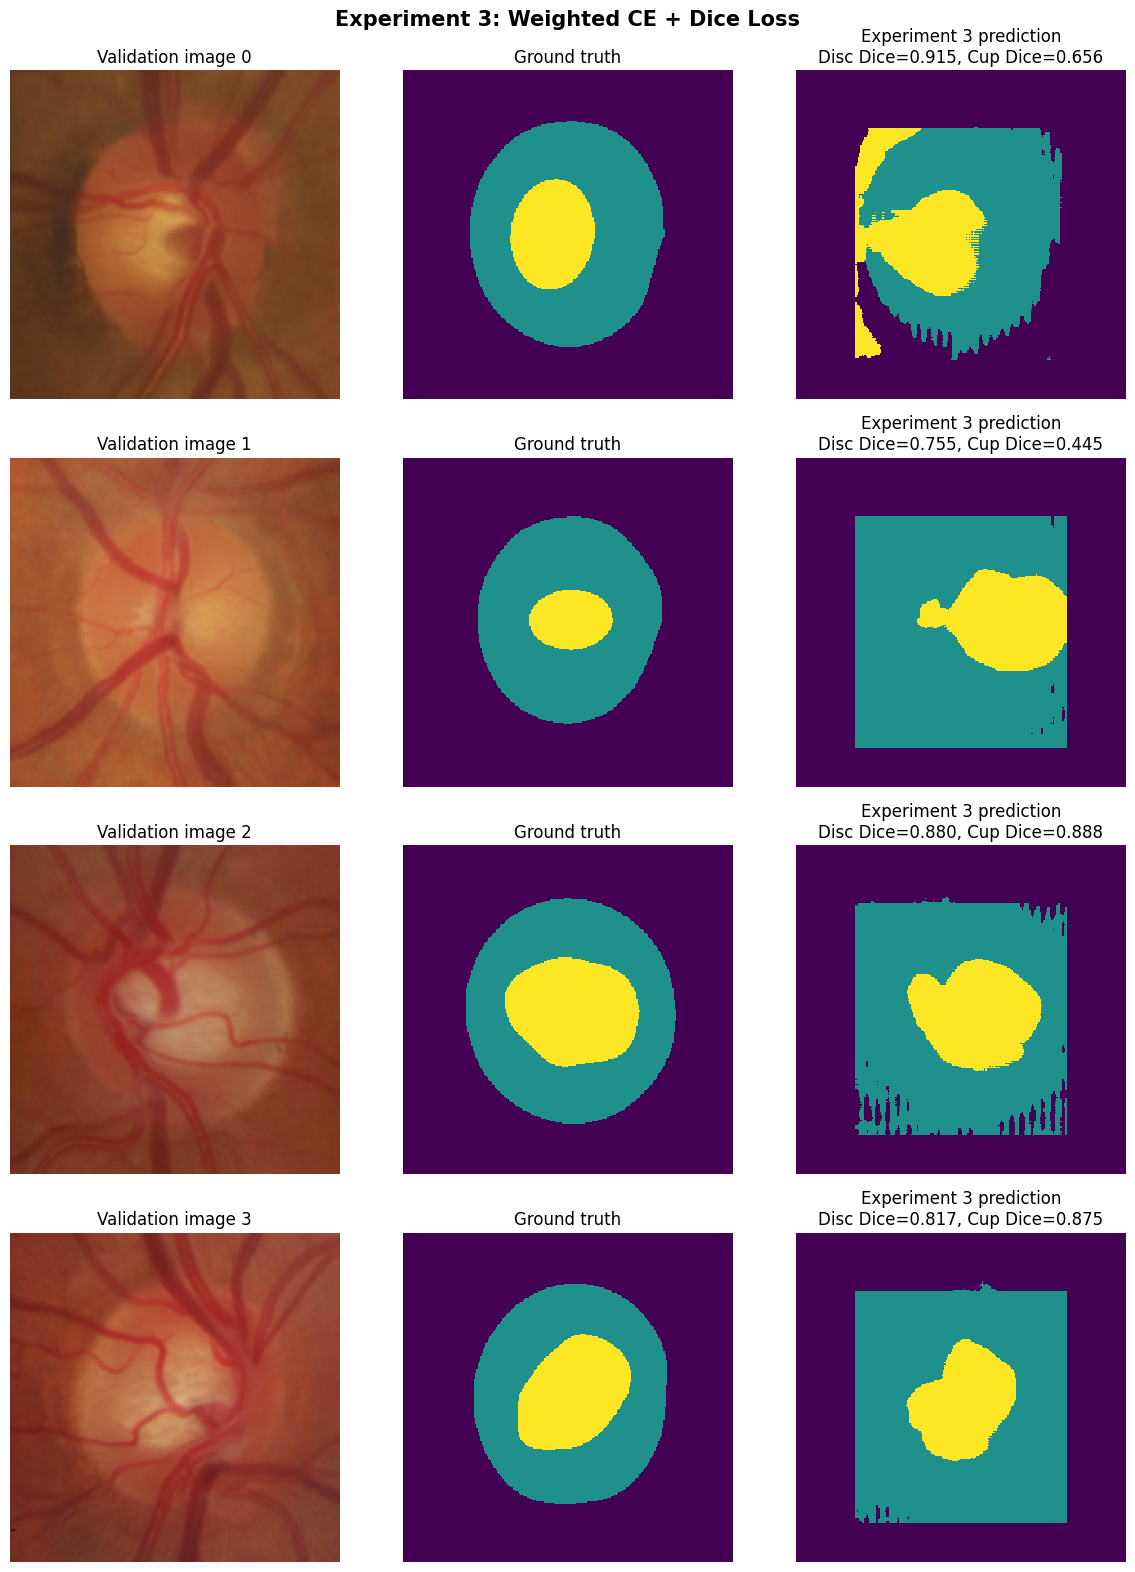


Visualization saved to:
/content/drive/MyDrive/CDR_Glaucoma/UNet_Results/combined_loss_experiment/validation_predictions_exp3.png


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset
import zipfile
import os

# Khởi tạo DEVICE nếu chưa có
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Giải nén lại dataset nếu chưa tồn tại trong /content
DATA_DIR = Path("/content/preprocessed_256")
if not DATA_DIR.exists():
    zip_path = Path("/content/drive/MyDrive/CDR_Glaucoma/segmentation_preprocessed_256.zip")
    if not zip_path.exists():
        # Thử đường dẫn thay thế nếu cấu trúc Drive khác biệt
        zip_path = Path("/content/drive/MyDrive/ET4248E_Glaucoma/segmentation_preprocessed_256.zip")

    if zip_path.exists():
        print(f"Dang giai nen: {zip_path}...")
        with zipfile.ZipFile(zip_path, "r") as z:
            for member in z.infolist():
                normalized_path = member.filename.replace("\\", "/")
                target_path = os.path.join("/content", normalized_path)
                if member.is_dir() or normalized_path.endswith("/"):
                    os.makedirs(target_path, exist_ok=True)
                else:
                    os.makedirs(os.path.dirname(target_path), exist_ok=True)
                    with z.open(member) as source, open(target_path, "wb") as target:
                        target.write(source.read())
        print("Giai nen hoan tat.")
    else:
        raise FileNotFoundError("Khong tim thay file ZIP cua dataset tren Google Drive. Vui long kiem tra lai duong dan.")

# Định nghĩa lại lớp FundusDataset để tránh lỗi thiếu biến khi nạp dữ liệu
class FundusDataset(Dataset):
    def __init__(self, split):
        self.image_dir = DATA_DIR / split / "images"
        self.mask_dir = DATA_DIR / split / "masks"
        self.images = sorted(self.image_dir.glob("*.png"))

        if not self.images:
            raise RuntimeError(f"Khong tim thay anh trong {split}")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_path = self.images[idx]
        mask_path = self.mask_dir / image_path.name

        with Image.open(image_path) as im:
            image = np.array(im.convert("RGB"), dtype=np.float32) / 255.0

        with Image.open(mask_path) as im:
            mask = np.array(im.convert("L"), dtype=np.uint8)

        image = torch.from_numpy(image.transpose(2, 0, 1).copy())
        mask = torch.from_numpy(mask.astype(np.int64))
        return image, mask

# Định nghĩa lại kiến trúc UNet
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(64, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = DoubleConv(128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = DoubleConv(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = DoubleConv(32, 16)
        self.out_conv = nn.Conv2d(16, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))
        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out_conv(d1)

# Khởi tạo model và val_ds
if 'model' not in globals():
    model = UNet(num_classes=3).to(DEVICE)

if 'val_ds' not in globals():
    val_ds = FundusDataset("validation")

# 1. Correct project path
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/CDR_Glaucoma/UNet_Results"
)
checkpoint_path = (
    OUTPUT_DIR / "combined_loss_experiment"
    / "best_unet_combined.pt"
)

assert checkpoint_path.exists(), (
    f"Checkpoint not found: {checkpoint_path}"
)

# 2. Load the best Experiment 3 checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Experiment 3 checkpoint loaded successfully.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

# 3. Calculate Dice score
def calculate_dice(pred_mask, true_mask):
    pred_mask = np.asarray(pred_mask, dtype=bool)
    true_mask = np.asarray(true_mask, dtype=bool)
    intersection = np.logical_and(pred_mask, true_mask).sum()
    denominator = pred_mask.sum() + true_mask.sum()
    if denominator == 0:
        return 1.0
    return 2.0 * intersection / denominator

# 4. Visualize 4 validation images
NUM_IMAGES = min(4, len(val_ds))

fig, axes = plt.subplots(
    NUM_IMAGES, 3,
    figsize=(12, 4 * NUM_IMAGES)
)

if NUM_IMAGES == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for i in range(NUM_IMAGES):
        image, true_mask = val_ds[i]

        logits = model(
            image.unsqueeze(0).to(DEVICE)
        )

        pred_mask = (
            logits.argmax(dim=1)[0]
            .cpu().numpy()
        )

        true = true_mask.cpu().numpy()

        # Disc = class 1 + class 2
        pred_disc = np.isin(pred_mask, [1, 2])
        true_disc = np.isin(true, [1, 2])

        # Cup = class 2
        pred_cup = pred_mask == 2
        true_cup = true == 2

        disc_dice = calculate_dice(pred_disc, true_disc)
        cup_dice = calculate_dice(pred_cup, true_cup)

        image_np = (
            image.cpu().permute(1, 2, 0).numpy()
        )

        # Original image
        axes[i, 0].imshow(
            np.clip(image_np, 0, 1)
        )
        axes[i, 0].set_title(
            f"Validation image {i}"
        )

        # Ground truth
        axes[i, 1].imshow(
            true, vmin=0, vmax=2,
            cmap="viridis",
            interpolation="nearest"
        )
        axes[i, 1].set_title(
            "Ground truth"
        )

        # Experiment 3 prediction
        axes[i, 2].imshow(
            pred_mask, vmin=0, vmax=2,
            cmap="viridis",
            interpolation="nearest"
        )
        axes[i, 2].set_title(
            "Experiment 3 prediction\n"
            f"Disc Dice={disc_dice:.3f}, "
            f"Cup Dice={cup_dice:.3f}"
        )

        for ax in axes[i]:
            ax.axis("off")

plt.suptitle(
    "Experiment 3: Weighted CE + Dice Loss",
    fontsize=15,
    fontweight="bold"
)
plt.tight_layout()

# 5. Save the visualization
save_path = (
    OUTPUT_DIR / "combined_loss_experiment"
    / "validation_predictions_exp3.png"
)
save_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nVisualization saved to:")
print(save_path)